In [4]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import sys, os
sys.path.append(os.path.abspath(".."))
from model import DownstreamModel

DATASETS = ["BCI2A"]
CHANNEL_MODE = "mapped"
DOWNSTREAM_CKPT = "/home/infres/yrothlin-24/EEG_Foundation_Model/outputs/downstream/tests/downstream_best.pt"

datasets = {
    "PHYSIONETMI": {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/PHYSIONETMI/physionetmi.lmdb", "n_classes": 4},
    "SLEEPEDFX":   {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/SLEEPEDF/sleepedf.lmdb", "n_classes": 5},
    "SEEDV":       {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/SEEDV/seedv.lmdb", "n_classes": 5},
    "BCI2A":       {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/BCI2A/bci2a.lmdb", "n_classes": 4},
    "TUAB":        {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/TUAB/tuab.lmdb", "n_classes": 2},
    "FACED":       {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/FACED/faced.lmdb", "n_classes": 9},
    "KARAONE":     {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/KARAONE/karaone.lmdb", "n_classes": 11},
    "BCI2020":     {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/BCI2020/bci2020.lmdb", "n_classes": 5},
    "CHISCO":      {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/CHISCO/chisco.lmdb", "n_classes": 39},
    "SIENA":       {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/SIENA/siena.lmdb", "n_classes": 2},
    "SHUMI":       {"dataset_path": "/projects/EEG-foundation-model/RECH202/data_preprocessed/SHUMI/shumi.lmdb", "n_classes": 2},
}

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(100)
print("device:", device, "| datasets:", DATASETS)


device: cuda | datasets: ['BCI2A']


In [5]:
import torch
from model import DownstreamModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# probe/head matching configs/downstream.yaml (heads.eegvae) used to train DOWNSTREAM_CKPT
PROBE = "eegvae"
PROBE_CONFIG = dict(
    pooling="mean_max", n_layer=2, hidden_dim=128, dropout=0.2,
    norm="layernorm", temporal_kernel_size=5, pyramid_bins=4,
)

def load_downstream_model(ckpt_path, num_classes):
    backbone_config = {
        "in_channels": 19, "out_channels": 19, "adaptor_layers": 4,
        "ch": 64, "ch_mult": [1, 2, 4, 8], "n_blocks": 2,
        "dropout": 0.0, "mode": "vq", "num_embeddings": 256,
        "commitment_cost": 0.25, "decay": 0.99,
    }
    sd = torch.load(ckpt_path, map_location="cpu")["model"]
    q = [k for k in sd
         if k.startswith("autoencoder.posterior.quantize.quantizers.") and k.endswith(".embedding")]
    backbone_config["z_channels"] = sd[q[0]].shape[1]
    backbone_config["n_quantizers"] = len({int(k.split(".quantizers.")[1].split(".")[0]) for k in q})

    model = DownstreamModel(
        backbone_config=backbone_config, num_classes=num_classes,
        freeze_backbone=True, freeze_channel_adaptor=False,
        probe=PROBE, probe_config=PROBE_CONFIG,
    ).to(device).eval()
    model.load_state_dict(sd)  
    for p in model.parameters():
        p.requires_grad = False
    return model

model = load_downstream_model(DOWNSTREAM_CKPT, num_classes=datasets[DATASETS[0]]["n_classes"])


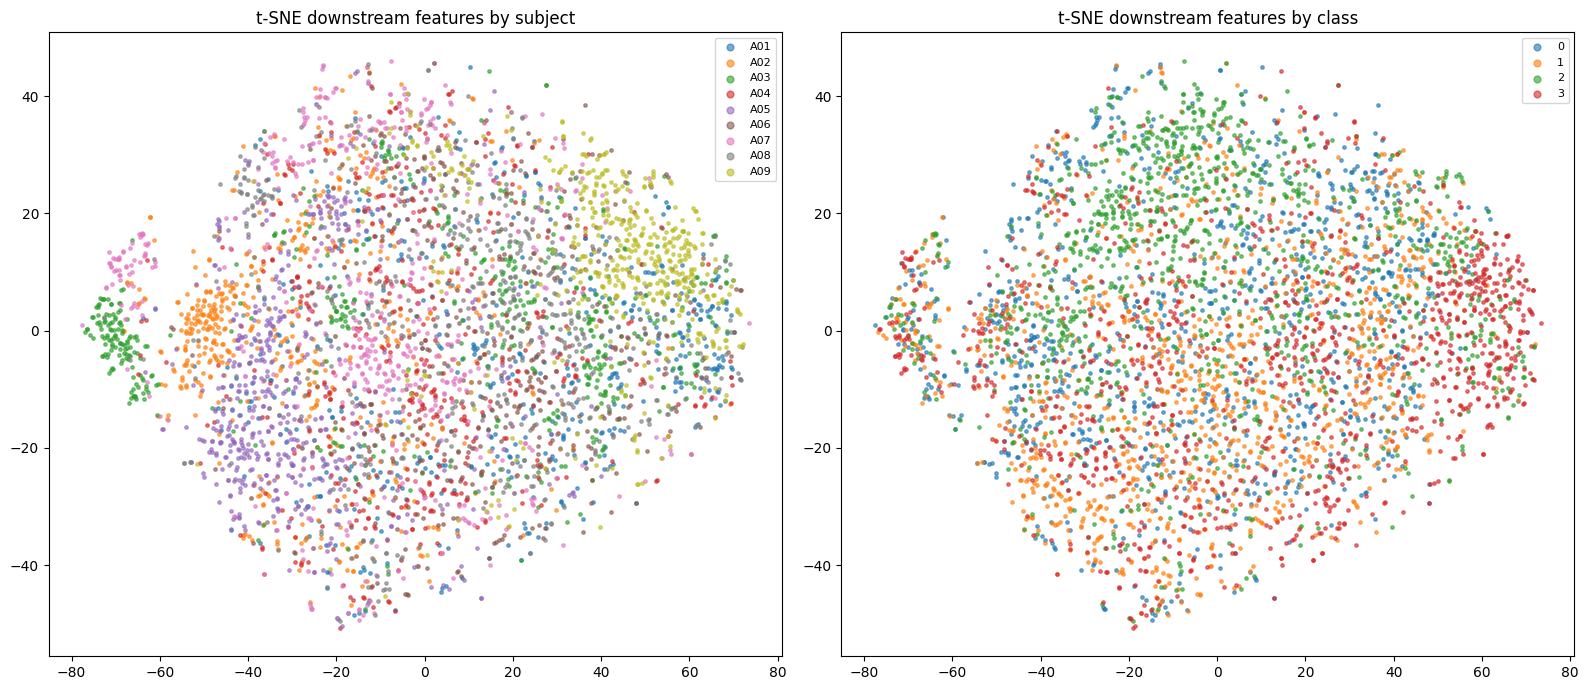

In [6]:
from pathlib import Path
import numpy as np
from sklearn.manifold import TSNE
from eeg_preprocessing.loaders import CustomDataset, get_subject_ids
from torch.utils.data import DataLoader

@torch.no_grad()
def extract_downstream_features(model, lmdb_path, device, channel_mode="mapped"):
    model.eval()
    feats, labels, subjects = [], [], []
    for sid in get_subject_ids(Path(lmdb_path)):
        ds = CustomDataset(lmdb_path, subject_ids=[sid], channel_mode=channel_mode)
        loader = DataLoader(ds, batch_size=256, num_workers=4)
        for x, y in loader:
            f = model.extract_features(x.to(device).float())
            feats.append(f.cpu().numpy())
            labels.append(y.numpy())
            subjects.append(np.full(len(y), sid))
    return np.concatenate(feats), np.concatenate(labels), np.concatenate(subjects)

LMDB = datasets[DATASETS[0]]["dataset_path"]

emb, y, subj = extract_downstream_features(model, LMDB, device=device, channel_mode=CHANNEL_MODE)
proj = TSNE(n_components=2, init="pca", perplexity=30).fit_transform(emb)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for sid in np.unique(subj):
    m = subj == sid
    axes[0].scatter(proj[m, 0], proj[m, 1], s=6, alpha=0.6, label=str(sid))
axes[0].set_title("t-SNE downstream features by subject")
axes[0].legend(markerscale=2, fontsize=8, loc="best")
for c in np.unique(y):
    m = y == c
    axes[1].scatter(proj[m, 0], proj[m, 1], s=6, alpha=0.6, label=str(c))
axes[1].set_title("t-SNE downstream features by class")
axes[1].legend(markerscale=2, fontsize=8, loc="best")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

sil_subject = silhouette_score(emb, subj)
sil_class = silhouette_score(emb, y)
print("silhouette by subject:", sil_subject)
print("silhouette by class:", sil_class)
